# Clasificación de textos con una RNN (BiLSTM): comparación de 5 modelos y barrido de hiperparámetros

Basado en el tutorial *Text classification with an RNN* de TensorFlow (Apache 2.0), adaptado de clasificación binaria a **multiclase** con `Combined_Data_es-ES.csv` (texto en español → 7 clases: Anxiety, Bipolar, Depression, Normal, Personality disorder, Stress, Suicidal).

Este cuaderno ejecuta **de arriba abajo** todos los experimentos y los consolida al final:

| Sección | Qué hace |
|---|---|
| 1 | Librerías y **dataset** (celda 1.2: aquí se sube o vincula) |
| 2 | Protocolo (semillas, particiones, qué grupos ejecutar) |
| 3 | Limpieza y partición train / val / test |
| 4 | **Plan de experimentos: aquí se modifican los hiperparámetros** (valores base, 5 modelos y barrido) |
| 5 | Funciones de entrenamiento y evaluación |
| 6 | Ejecución del plan (guarda un CSV después de cada experimento y retoma donde quedó) |
| 7 | Consolidación: tablas y gráficos para el informe |
| 8 | Modelo ganador: repetición con varias semillas y evaluación **única** en test |
| 9 | Predicción sobre un texto nuevo |

**Diseño experimental.** Todas las comparaciones se hacen sobre el conjunto de **validación**. El conjunto de test se usa una sola vez, en la sección 8, con la configuración ganadora. El plan tiene dos partes: **5 modelos** que agrupan cambios con una misma idea (M1 a M5) y un **barrido** que cambia una variable a la vez (o un par acoplado, como optimizador + learning rate) a partir del modelo base. Los modelos dicen qué estrategia ayuda; el barrido, qué hiperparámetro lo hace.

Activa GPU antes de empezar: *Entorno de ejecución → Cambiar tipo de entorno de ejecución*.

## 1. Preparación

### 1.1 Librerías

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.2 Dataset: dónde subirlo o vincularlo, y dónde se guardan los resultados

Con tantos experimentos, conviene que los resultados queden en un lugar que **sobreviva a una desconexión de Colab**. Por eso el modo recomendado es `"drive"`:

- **`MODO_CARGA = "drive"`** (recomendado): sube antes `Combined_Data_es-ES.csv` a tu Google Drive, ajusta `RUTA_DRIVE` a su ubicación y autoriza el acceso cuando Colab lo pida. Los resultados se guardan en `CARPETA_DRIVE`.
- **`MODO_CARGA = "subir"`**: al ejecutar la celda aparece un botón *Elegir archivos*; selecciona el CSV. Los resultados se guardan en el disco temporal de Colab y **se pierden si la sesión se reinicia**.

In [ ]:
# ══════════ AQUÍ SE SUBE / VINCULA EL DATASET ══════════
MODO_CARGA = "drive"      # "drive" (recomendado) | "subir" (botón de carga)
RUTA_DRIVE = "/content/drive/MyDrive/Combined_Data_es-ES.csv"   # solo si MODO_CARGA = "drive"
CARPETA_DRIVE = "/content/drive/MyDrive/resultados_rnn"         # carpeta de resultados (modo "drive")

if MODO_CARGA == "subir":
    from google.colab import files
    archivos = files.upload()             # elige Combined_Data_es-ES.csv
    RUTA_CSV = next(iter(archivos))
    CARPETA_RESULTADOS = "/content/resultados_rnn"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_CSV = RUTA_DRIVE
    CARPETA_RESULTADOS = CARPETA_DRIVE

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
print("Dataset en:", RUTA_CSV)
print("Resultados en:", CARPETA_RESULTADOS)

Mounted at /content/drive
Dataset en: /content/drive/MyDrive/Combined_Data_es-ES.csv
Resultados en: /content/drive/MyDrive/resultados_rnn


## 2. Protocolo experimental

Estos valores **no son hiperparámetros del modelo** y no deben cambiar entre experimentos; si cambian, los resultados dejan de ser comparables. Los hiperparámetros están en la sección 4.

In [ ]:
SEED_PARTICION = 42            # semilla de la partición train / val / test
FRAC_VAL = 0.15
FRAC_TEST = 0.15
SEEDS_FINALES = [42, 43, 44]   # semillas con las que se repite el modelo ganador (sección 8)

# ── Control de ejecución ──
GRUPOS_A_EJECUTAR = {"modelos": True, "barrido": True}   # apaga un grupo poniéndolo en False
SOLO_ESTOS = None              # None = todo el plan; o una lista de nombres, p. ej. ["base", "M1_representacion"]
REINICIAR_RESULTADOS = False   # True = ignora los resultados guardados y empieza de cero

## 3. Datos: limpieza y partición

Se limpia **antes** de dividir (nulos, textos vacíos, textos repetidos y textos repetidos con etiquetas distintas), de modo que un mismo texto no pueda quedar a la vez en train y en test. La partición es estratificada: cada conjunto conserva la proporción de clases.

In [ ]:
df = pd.read_csv(RUTA_CSV, usecols=["statement_es_es", "status"]).rename(
    columns={"statement_es_es": "texto", "status": "clase"})
n_inicial = len(df)

df = df.dropna(subset=["texto"])
df = df[df["texto"].str.strip() != ""]
conflicto = df.groupby("texto")["clase"].nunique()
df = df[~df["texto"].isin(conflicto[conflicto > 1].index)].drop_duplicates("texto")
print(f"Filas: {n_inicial} -> {len(df)} tras la limpieza")

# Etiquetas enteras 0..6
nombres_clase = sorted(df["clase"].unique())
df["y"] = df["clase"].map({c: i for i, c in enumerate(nombres_clase)})
NUM_CLASSES = len(nombres_clase)

# Partición estratificada
train_df, temp_df = train_test_split(df, test_size=FRAC_VAL + FRAC_TEST,
                                     stratify=df["y"], random_state=SEED_PARTICION)
val_df, test_df = train_test_split(temp_df, test_size=FRAC_TEST / (FRAC_VAL + FRAC_TEST),
                                   stratify=temp_df["y"], random_state=SEED_PARTICION)

# Pesos por clase (calculados solo con train)
pesos = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"])
class_weight = dict(enumerate(pesos))

print(f"NUM_CLASSES = {NUM_CLASSES}: {nombres_clase}")
print(f"train / val / test: {len(train_df)} / {len(val_df)} / {len(test_df)}")
print("\nProporción por clase (%):")
print(pd.DataFrame({n: d["clase"].value_counts(normalize=True).mul(100).round(1)
                    for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}))

Filas: 53043 -> 52309 tras la limpieza
NUM_CLASSES = 7: ['Anxiety', 'Bipolar', 'Depression', 'Normal', 'Personality disorder', 'Stress', 'Suicidal']
train / val / test: 36616 / 7846 / 7847

Proporción por clase (%):
                      train   val  test
clase                                  
Normal                 30.8  30.8  30.8
Depression             29.2  29.2  29.2
Suicidal               20.2  20.2  20.2
Anxiety                 7.3   7.4   7.3
Bipolar                 5.3   5.3   5.3
Stress                  4.9   4.9   4.9
Personality disorder    2.1   2.1   2.1


## 4. Plan de experimentos (aquí se modifican los hiperparámetros)

Esta es la única celda donde se editan los hiperparámetros. Tiene tres bloques:

1. **`BASE`**: valores del modelo inicial. Es el punto de partida de todos los experimentos.
2. **`MODELOS`**: los 5 modelos. Cada uno lista **solo lo que cambia** respecto a `BASE`.
3. **`BARRIDO`**: cada hiperparámetro con los valores a probar, **uno a la vez** respecto a `BASE`. Si una entrada tiene dos variables, es un par acoplado que se mueve junto (por ejemplo, `OPTIMIZER` y `LEARNING_RATE`).

Para cambiar un experimento, edita su línea. Si ya lo habías ejecutado, el cuaderno detecta que la configuración cambió y lo vuelve a correr.

In [ ]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  ZONA DE HIPERPARÁMETROS — modifica solo esta celda                  ║
# ╚══════════════════════════════════════════════════════════════════════╝

# ── 1) MODELO BASE (valores del cuaderno original) ──
BASE = dict(
    VOCAB_SIZE=1000,                 # tamaño del vocabulario                (se usa en 5.2, TextVectorization)
    MAX_LEN=None,                    # longitud máxima; None = sin límite    (5.2)
    EMBEDDING_DIM=64,                # dimensión del embedding               (5.3, Embedding)
    LSTM_UNITS=64,                   # unidades del LSTM                     (5.3, LSTM)
    DENSE_UNITS=64,                  # unidades de la Dense oculta           (5.3, Dense)
    DROPOUT_RATE=0.0,                # dropout tras la BiLSTM (0 = sin dropout) (5.3, Dropout)
    OPTIMIZER="adam",                # "adam" | "rmsprop" | "sgd"            (5.4, compile)
    LEARNING_RATE=1e-4,              # learning rate                         (5.4)
    BATCH_SIZE=64,                   # tamaño de lote                        (5.1, batch)
    EPOCHS=10,                       # épocas (tope si hay early stopping)   (5.4, fit)
    PACIENCIA_EARLY_STOPPING=None,   # None = desactivado                    (5.4, EarlyStopping)
    USAR_CLASS_WEIGHT=True,          # pondera las clases por su frecuencia  (5.4, fit)
    BUFFER_SIZE=10000,               # buffer del shuffle (impacto bajo)     (5.1, shuffle)
    SEED_ENTRENAMIENTO=42,           # semilla de entrenamiento              (5.1)
)

# ── 2) LOS 5 MODELOS (solo se listan los cambios respecto a BASE) ──
MODELOS = {
    "M1_representacion": dict(VOCAB_SIZE=10000, MAX_LEN=256),
    "M2_optimizacion": dict(LEARNING_RATE=1e-3, EPOCHS=30, PACIENCIA_EARLY_STOPPING=3),
    "M3_capacidad_regularizacion": dict(EMBEDDING_DIM=128, LSTM_UNITS=128, DENSE_UNITS=128, DROPOUT_RATE=0.3),
    "M4_compacto": dict(EMBEDDING_DIM=32, LSTM_UNITS=32, DENSE_UNITS=32, MAX_LEN=128, BATCH_SIZE=128),
    "M5_combinacion": dict(VOCAB_SIZE=10000, MAX_LEN=256, LEARNING_RATE=1e-3, EPOCHS=30,
                           PACIENCIA_EARLY_STOPPING=3, DROPOUT_RATE=0.2),
}

# ── 3) BARRIDO: una variable a la vez respecto a BASE (de mayor a menor prioridad) ──
BARRIDO = {
    "VOCAB_SIZE":            [dict(VOCAB_SIZE=v) for v in (5000, 10000, 20000)],
    "LEARNING_RATE":         [dict(LEARNING_RATE=v) for v in (5e-4, 1e-3)],
    "USAR_CLASS_WEIGHT":     [dict(USAR_CLASS_WEIGHT=False)],
    "MAX_LEN":               [dict(MAX_LEN=v) for v in (128, 256, 512)],
    "EPOCHS + EARLY STOPPING": [dict(EPOCHS=30, PACIENCIA_EARLY_STOPPING=3)],
    "LSTM_UNITS":            [dict(LSTM_UNITS=v) for v in (32, 128)],
    "DROPOUT_RATE":          [dict(DROPOUT_RATE=v) for v in (0.2, 0.5)],
    "EMBEDDING_DIM":         [dict(EMBEDDING_DIM=v) for v in (32, 128)],
    "BATCH_SIZE":            [dict(BATCH_SIZE=v) for v in (32, 128)],
    "OPTIMIZER (+ LR en SGD)": [dict(OPTIMIZER="rmsprop"), dict(OPTIMIZER="sgd", LEARNING_RATE=1e-2)],
    "DENSE_UNITS":           [dict(DENSE_UNITS=v) for v in (32, 128)],
}

# ── Construcción del plan (no editar) ──
def etiqueta(cambios):
    return "+".join(f"{k}={v}" for k, v in cambios.items())

plan = {"base": {"grupo": "base", "cfg": dict(BASE)}}
if GRUPOS_A_EJECUTAR.get("modelos"):
    for nombre, cambios in MODELOS.items():
        plan[nombre] = {"grupo": "modelo", "cfg": {**BASE, **cambios}}
if GRUPOS_A_EJECUTAR.get("barrido"):
    for grupo_var, lista in BARRIDO.items():
        for cambios in lista:
            plan["barrido_" + etiqueta(cambios)] = {"grupo": "barrido", "cfg": {**BASE, **cambios}, "variable": grupo_var}

print(f"Plan: {len(plan)} experimentos "
      f"({sum(e['grupo']=='modelo' for e in plan.values())} modelos, "
      f"{sum(e['grupo']=='barrido' for e in plan.values())} del barrido, más el base)")

Plan: 28 experimentos (5 modelos, 22 del barrido, más el base)


## 5. Funciones de entrenamiento y evaluación

No hay nada que editar aquí. `correr_experimento` recibe una configuración y ejecuta el ciclo completo:

- **5.1** Pipeline de datos (`BATCH_SIZE`, `BUFFER_SIZE`, `SEED_ENTRENAMIENTO`).
- **5.2** Codificador de texto (`VOCAB_SIZE`, `MAX_LEN`). `TextVectorization` convierte cada texto en una secuencia de índices; su vocabulario se aprende **solo con el conjunto de entrenamiento**. Con `MAX_LEN = None`, cada lote se rellena hasta su texto más largo.
- **5.3** Modelo (`EMBEDDING_DIM`, `LSTM_UNITS`, `DROPOUT_RATE`, `DENSE_UNITS`).
- **5.4** Compilación y entrenamiento (`OPTIMIZER`, `LEARNING_RATE`, `EPOCHS`, `PACIENCIA_EARLY_STOPPING`, `USAR_CLASS_WEIGHT`).
- Evaluación en **validación** con accuracy y **macro-F1** (promedio del F1 de las 7 clases, que no se deja dominar por las clases grandes). Referencia: un modelo que siempre prediga la clase mayoritaria obtiene ≈ 31 % de accuracy.

In [ ]:
OPTIMIZADORES = {"adam": tf.keras.optimizers.Adam,
                 "rmsprop": tf.keras.optimizers.RMSprop,
                 "sgd": tf.keras.optimizers.SGD}

# 5.1 Pipeline de datos
def construir_datasets(cfg):
    def a_dataset(d, mezclar=False):
        ds = tf.data.Dataset.from_tensor_slices((d["texto"].values, d["y"].values.astype("int32")))
        if mezclar:
            ds = ds.shuffle(cfg["BUFFER_SIZE"], seed=cfg["SEED_ENTRENAMIENTO"])
        return ds.batch(cfg["BATCH_SIZE"]).prefetch(tf.data.AUTOTUNE)
    return a_dataset(train_df, True), a_dataset(val_df), a_dataset(test_df)

# 5.2 Codificador de texto
def construir_encoder(cfg):
    encoder = tf.keras.layers.TextVectorization(max_tokens=cfg["VOCAB_SIZE"],
                                                output_sequence_length=cfg["MAX_LEN"])
    encoder.adapt(train_df["texto"].values)
    return encoder

# 5.3 Modelo
def construir_modelo(cfg, encoder):
    modelo = tf.keras.Sequential([
        encoder,
        tf.keras.layers.Embedding(input_dim=len(encoder.get_vocabulary()),
                                  output_dim=cfg["EMBEDDING_DIM"],
                                  mask_zero=False),                         # mask_zero cambiado a False para evitar errores de cuDNN
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(cfg["LSTM_UNITS"])),
        tf.keras.layers.Dropout(cfg["DROPOUT_RATE"]),                       # con 0.0 no tiene efecto
        tf.keras.layers.Dense(cfg["DENSE_UNITS"], activation="relu"),
        tf.keras.layers.Dense(NUM_CLASSES),                                 # un logit por clase
    ])
    _ = modelo(tf.constant(["texto de ejemplo"]))                           # construye los pesos
    return modelo

# 5.4 Compilación, entrenamiento y evaluación en validación
def correr_experimento(nombre, cfg, grupo="", devolver_modelo=False, epochs=None):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(cfg["SEED_ENTRENAMIENTO"])
    train_ds, val_ds, _ = construir_datasets(cfg)
    encoder = construir_encoder(cfg)
    modelo = construir_modelo(cfg, encoder)

    modelo.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                   optimizer=OPTIMIZADORES[cfg["OPTIMIZER"]](cfg["LEARNING_RATE"]),
                   metrics=["accuracy"])
    callbacks = []
    if cfg["PACIENCIA_EARLY_STOPPING"] is not None:
        callbacks.append(tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=cfg["PACIENCIA_EARLY_STOPPING"], restore_best_weights=True))

    t0 = time.time()
    history = modelo.fit(train_ds, epochs=epochs or cfg["EPOCHS"], validation_data=val_ds,
                         class_weight=class_weight if cfg["USAR_CLASS_WEIGHT"] else None,
                         callbacks=callbacks, verbose=2)
    tiempo_s = time.time() - t0

    y_val = val_df["y"].values
    y_pred = np.argmax(modelo.predict(val_ds, verbose=0), axis=-1)
    fila = {"experimento": nombre, "grupo": grupo, **cfg,
            "epocas_ejecutadas": len(history.history["loss"]),
            "parametros": modelo.count_params(),
            "tiempo_s": round(tiempo_s),
            "val_loss": round(float(modelo.evaluate(val_ds, verbose=0)[0]), 4),
            "val_accuracy": round(accuracy_score(y_val, y_pred), 4),
            "val_macro_f1": round(f1_score(y_val, y_pred, average="macro"), 4)}
    for c, f in zip(nombres_clase, f1_score(y_val, y_pred, average=None, labels=range(NUM_CLASSES))):
        fila["f1_" + c] = round(f, 4)
    print(f"→ {nombre}: val accuracy = {fila["val_accuracy"]:.3f} | val macro-F1 = {fila["val_macro_f1"]:.3f} "
          f"| {fila["epocas_ejecutadas"]} épocas | {fila["tiempo_s"]} s")

    if devolver_modelo:
        return {"fila": fila, "modelo": modelo, "history": history}
    return {"fila": fila}

### 5.5 (Opcional) Medir el tiempo antes de lanzar todo el plan

Entrena **una época** del modelo base y estima el tiempo total. Es una cota aproximada: los modelos con `MAX_LEN` o menos unidades serán más rápidos, y los que usan early stopping suelen parar antes de su tope de épocas.

In [ ]:
prueba = correr_experimento("_prueba_tiempo", BASE, epochs=1)["fila"]
epocas_plan = sum(e["cfg"]["EPOCHS"] for n, e in plan.items() if SOLO_ESTOS is None or n in SOLO_ESTOS)
print(f"\n1 época del base ≈ {prueba['tiempo_s']} s")
print(f"El plan suma {epocas_plan} épocas como máximo → cota aproximada ≈ {epocas_plan * prueba['tiempo_s'] / 3600:.1f} h")

573/573 - 37s - 64ms/step - accuracy: 0.3500 - loss: 1.7805 - val_accuracy: 0.3588 - val_loss: 1.5709
→ _prueba_tiempo: val accuracy = 0.359 | val macro-F1 = 0.224 | 1 épocas | 37 s

1 época del base ≈ 37 s
El plan suma 340 épocas como máximo → cota aproximada ≈ 3.5 h


## 6. Ejecución del plan

Entrena los experimentos pendientes uno detrás de otro. Después de **cada uno** se guarda `resultados_experimentos.csv` en la carpeta de resultados, así que si Colab se desconecta basta con volver a ejecutar desde la sección 1: los experimentos terminados se saltan y se retoma el siguiente.

In [ ]:
RUTA_RESULTADOS = os.path.join(CARPETA_RESULTADOS, "resultados_experimentos.csv")
firma = lambda cfg: json.dumps(cfg, sort_keys=True)     # identifica la configuración de cada experimento

if os.path.exists(RUTA_RESULTADOS) and not REINICIAR_RESULTADOS:
    resultados_df = pd.read_csv(RUTA_RESULTADOS)
else:
    resultados_df = pd.DataFrame()

hechos = {} if resultados_df.empty else dict(zip(resultados_df["experimento"], resultados_df["firma"]))
pendientes = [n for n, e in plan.items()
              if (SOLO_ESTOS is None or n in SOLO_ESTOS) and hechos.get(n) != firma(e["cfg"])]
print(f"Ya hechos: {len(hechos)} | pendientes: {len(pendientes)}")

for i, nombre in enumerate(pendientes, 1):
    e = plan[nombre]
    print(f"\n=== [{i}/{len(pendientes)}] {nombre} ===")
    fila = correr_experimento(nombre, e["cfg"], grupo=e["grupo"])["fila"]
    fila["firma"] = firma(e["cfg"])
    if resultados_df.empty:
        resultados_df = pd.DataFrame([fila])
    else:
        resultados_df = pd.concat([resultados_df[resultados_df["experimento"] != nombre],
                                   pd.DataFrame([fila])], ignore_index=True)
    resultados_df.to_csv(RUTA_RESULTADOS, index=False)       # guardado progresivo

print("\nListo. Resultados en:", RUTA_RESULTADOS)

Ya hechos: 28 | pendientes: 0

Listo. Resultados en: /content/drive/MyDrive/resultados_rnn/resultados_experimentos.csv


## 7. Consolidación de resultados

Todo se calcula sobre el conjunto de **validación**. `delta_vs_base` es la diferencia de macro-F1 respecto al modelo base.

### 7.1 Tabla general (ordenada por macro-F1)

In [ ]:
res = resultados_df.copy()
f1_base = res.loc[res["experimento"] == "base", "val_macro_f1"]
res["delta_vs_base"] = (res["val_macro_f1"] - f1_base.iloc[0]).round(4) if len(f1_base) else np.nan
res = res.sort_values("val_macro_f1", ascending=False).reset_index(drop=True)

columnas = ["experimento", "grupo", "val_macro_f1", "val_accuracy", "val_loss", "delta_vs_base",
            "parametros", "epocas_ejecutadas", "tiempo_s"]
display(res[columnas])
res.drop(columns=["firma"]).to_csv(os.path.join(CARPETA_RESULTADOS, "resultados_consolidados.csv"), index=False)

,experimento,grupo,val_macro_f1,val_accuracy,val_loss,delta_vs_base,parametros,epocas_ejecutadas,tiempo_s
0,M5_combinacion,modelo,0.6058,0.6612,0.9063,0.1091,714759,7,110
1,M2_optimizacion,modelo,0.5541,0.6396,0.9690,0.0574,138759,6,182
2,barrido_LEARNING_RATE=0.001,barrido,0.5488,0.6210,1.0533,0.0521,138759,10,298
3,barrido_LEARNING_RATE=0.0005,barrido,0.5448,0.6083,1.0888,0.0481,138759,10,306
4,barrido_VOCAB_SIZE=10000,barrido,0.5445,0.6073,1.0934,0.0478,714759,10,314
5,barrido_VOCAB_SIZE=5000,barrido,0.5433,0.6036,1.0859,0.0466,394759,10,296
6,barrido_VOCAB_SIZE=20000,barrido,0.5347,0.5979,1.1491,0.0380,1354759,10,286
7,M3_capacidad_regularizacion,modelo,0.5326,0.6031,1.0586,0.0359,424967,10,389
8,M1_representacion,modelo,0.5265,0.5836,1.1299,0.0298,714759,10,142
9,barrido_EMBEDDING_DIM=128,barrido,0.5225,0.5965,1.0981,0.0258,235527,10,320


### 7.2 Los 5 modelos frente al base

In [ ]:
hiperparametros = list(BASE.keys())
modelos_df = res[res["grupo"].isin(["base", "modelo"])].sort_values("experimento", key=lambda col: col.map(lambda x: "" if x == "base" else x))
display(modelos_df[["experimento"] + hiperparametros + ["val_macro_f1", "val_accuracy", "delta_vs_base"]]
        .set_index("experimento").T)

experimento,base,M1_representacion,M2_optimizacion,M3_capacidad_regularizacion,M4_compacto,M5_combinacion
VOCAB_SIZE,1000,10000,1000,1000,1000,10000
MAX_LEN,NaN,256.0,NaN,NaN,128.0,256.0
EMBEDDING_DIM,64,64,64,128,32,64
LSTM_UNITS,64,64,64,128,32,64
DENSE_UNITS,64,64,64,128,32,64
DROPOUT_RATE,0.0,0.0,0.0,0.3,0.0,0.2
OPTIMIZER,adam,adam,adam,adam,adam,adam
LEARNING_RATE,0.0001,0.0001,0.001,0.0001,0.0001,0.001
BATCH_SIZE,64,64,64,64,128,64
EPOCHS,10,10,30,10,10,30


### 7.3 Ranking de todos los experimentos

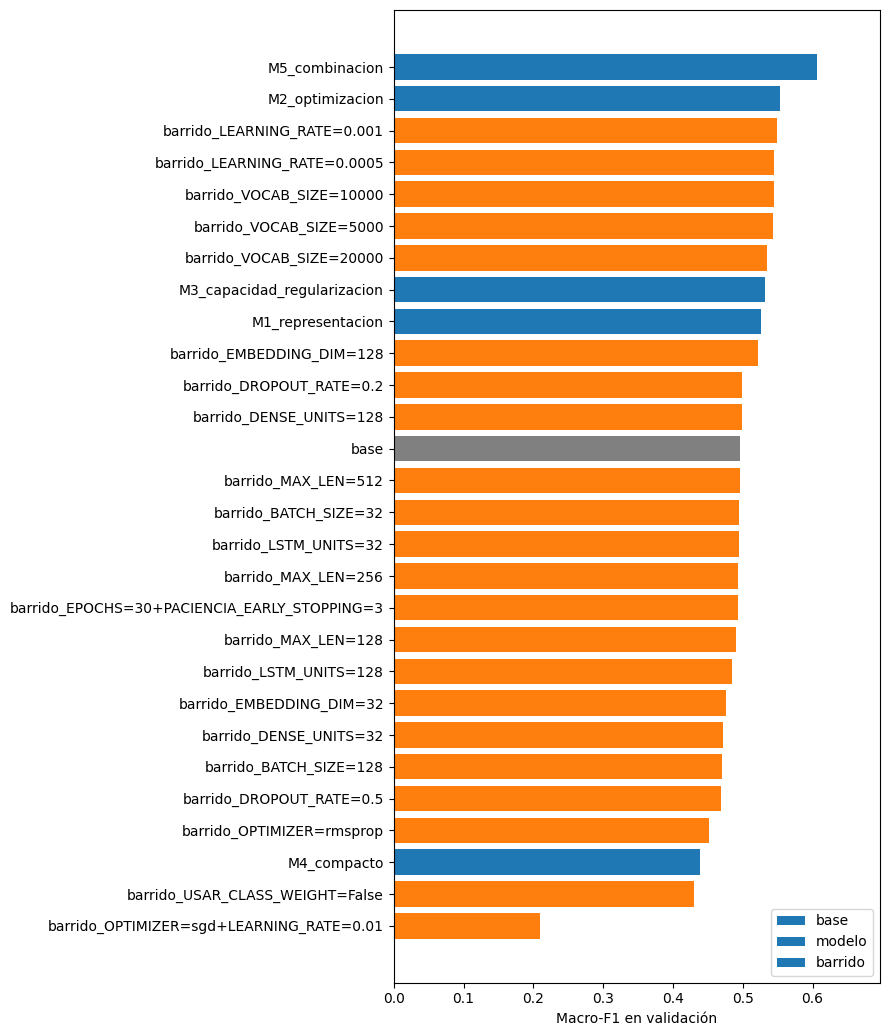

In [ ]:
colores = {"base": "gray", "modelo": "tab:blue", "barrido": "tab:orange"}
d = res.sort_values("val_macro_f1")
fig, eje = plt.subplots(figsize=(9, 0.32 * len(d) + 1.5))
eje.barh(d["experimento"], d["val_macro_f1"], color=[colores.get(g, "tab:green") for g in d["grupo"]])
eje.set_xlabel("Macro-F1 en validación")
eje.set_xlim(0, max(0.05, d["val_macro_f1"].max() * 1.15))
for g, c in colores.items():
    eje.barh([], [], color=c, label=g)
eje.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 7.4 Barrido: efecto de cada hiperparámetro (uno a la vez)

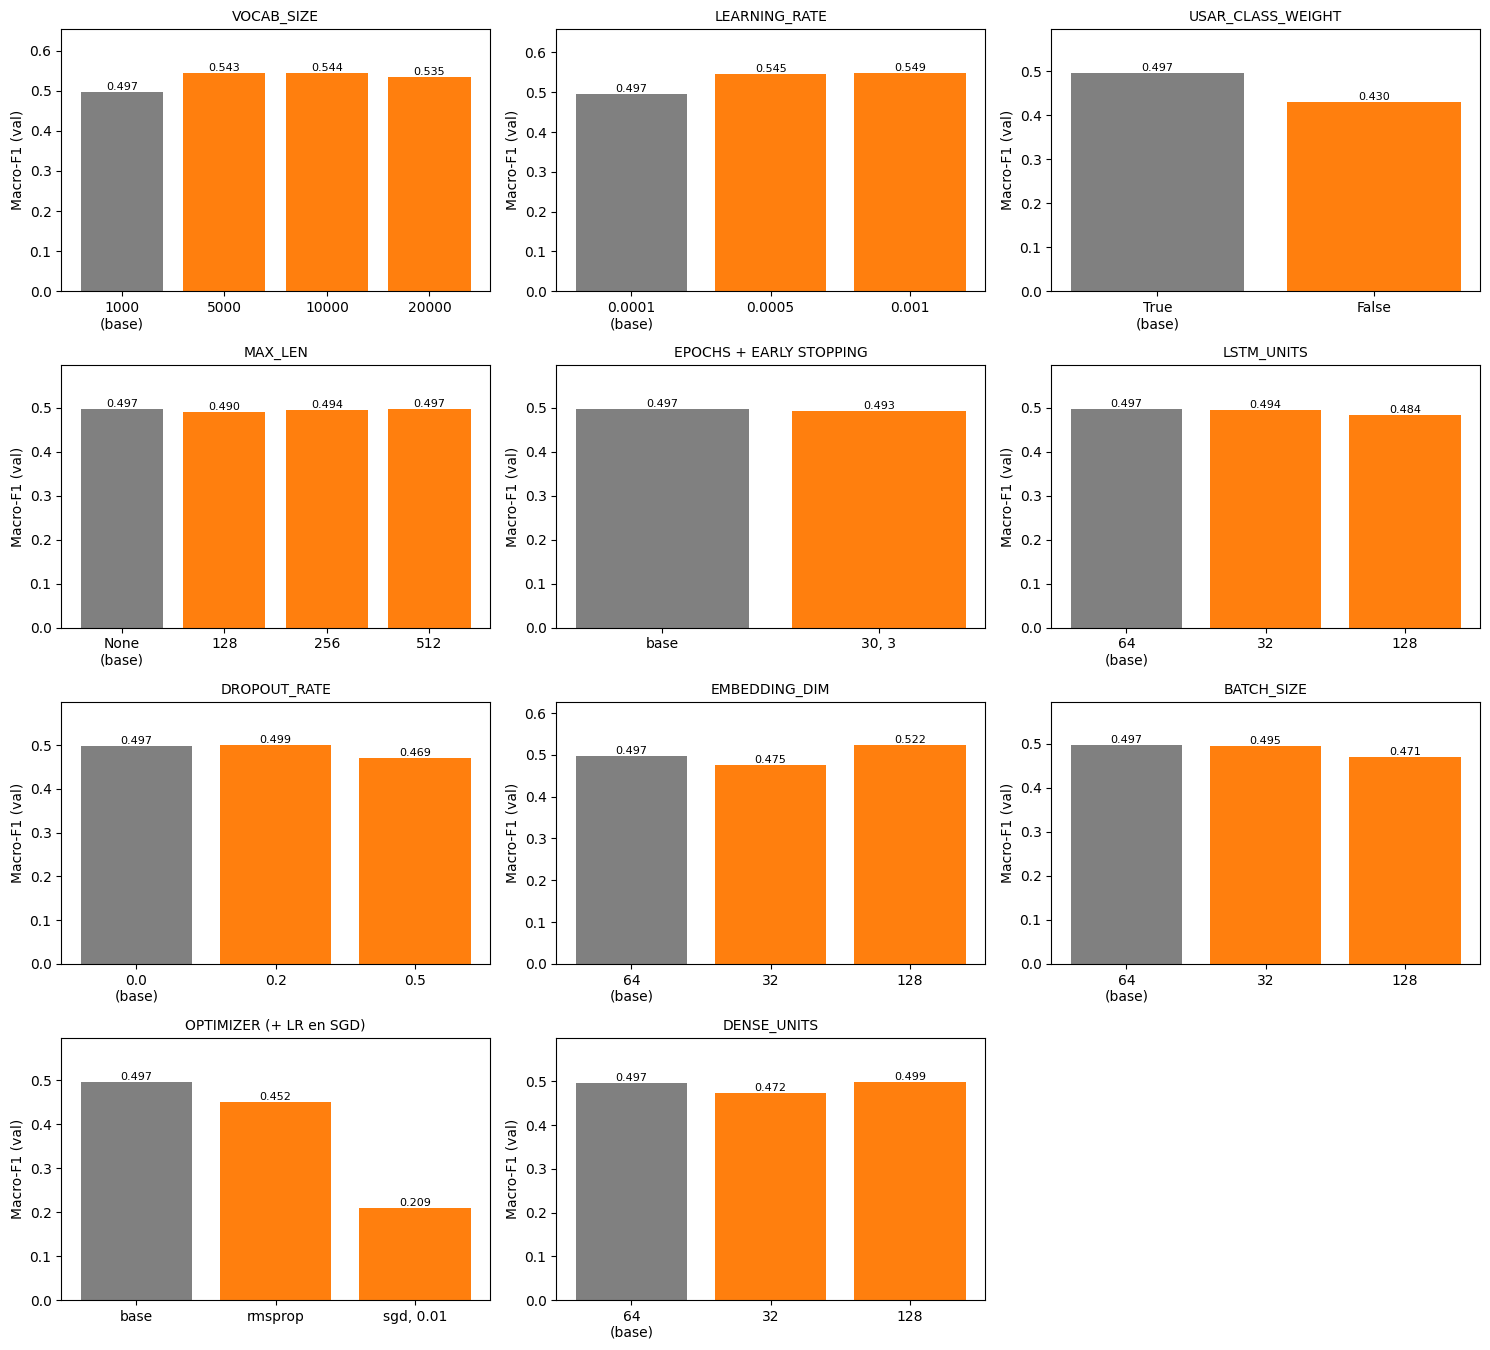

In [ ]:
f1 = dict(zip(res["experimento"], res["val_macro_f1"]))
grupos = [g for g in BARRIDO if any(("barrido_" + etiqueta(c)) in f1 for c in BARRIDO[g])]

if "base" in f1 and grupos:
    columnas_fig = 3
    filas_fig = -(-len(grupos) // columnas_fig)
    fig, ejes = plt.subplots(filas_fig, columnas_fig, figsize=(5 * columnas_fig, 3.4 * filas_fig), squeeze=False)
    for eje in ejes.flat:
        eje.axis("off")
    for eje, g in zip(ejes.flat, grupos):
        eje.axis("on")
        lista = [c for c in BARRIDO[g] if ("barrido_" + etiqueta(c)) in f1]
        una_variable = all(len(c) == 1 for c in lista) and len({k for c in lista for k in c}) == 1
        if una_variable:
            clave = next(iter(lista[0]))
            etiquetas = [f"{BASE[clave]}\n(base)"] + [str(next(iter(c.values()))) for c in lista]
        else:
            etiquetas = ["base"] + [", ".join(str(v) for v in c.values()) for c in lista]
        valores = [f1["base"]] + [f1["barrido_" + etiqueta(c)] for c in lista]
        barras = eje.bar(etiquetas, valores, color=["gray"] + ["tab:orange"] * len(lista))
        eje.bar_label(barras, fmt="%.3f", fontsize=8)
        eje.set_title(g, fontsize=10)
        eje.set_ylim(0, max(valores) * 1.2)
        eje.set_ylabel("Macro-F1 (val)")
    plt.tight_layout(); plt.show()
else:
    print("Aún no hay resultados del barrido (o falta el modelo base).")

### 7.5 F1 por clase: base y los 5 modelos

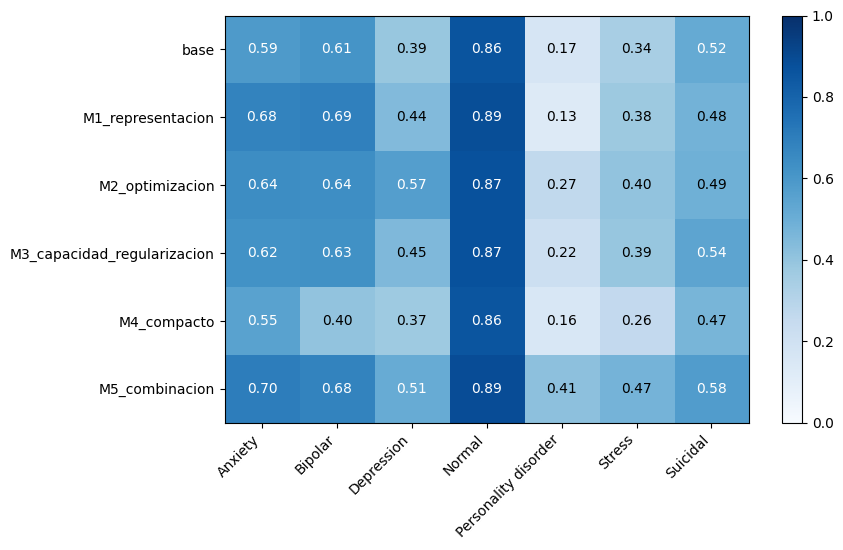

In [ ]:
cols_f1 = ["f1_" + c for c in nombres_clase]
sub = res[res["grupo"].isin(["base", "modelo"])].sort_values("experimento", key=lambda col: col.map(lambda x: "" if x == "base" else x))
if len(sub):
    fig, eje = plt.subplots(figsize=(9, 0.6 * len(sub) + 2))
    im = eje.imshow(sub[cols_f1].values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    eje.set_xticks(range(NUM_CLASSES)); eje.set_xticklabels(nombres_clase, rotation=45, ha="right")
    eje.set_yticks(range(len(sub))); eje.set_yticklabels(sub["experimento"])
    for i in range(len(sub)):
        for j in range(NUM_CLASSES):
            v = sub[cols_f1].values[i, j]
            eje.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black")
    plt.colorbar(im); plt.tight_layout(); plt.show()

### 7.6 Tamaño del modelo frente al desempeño

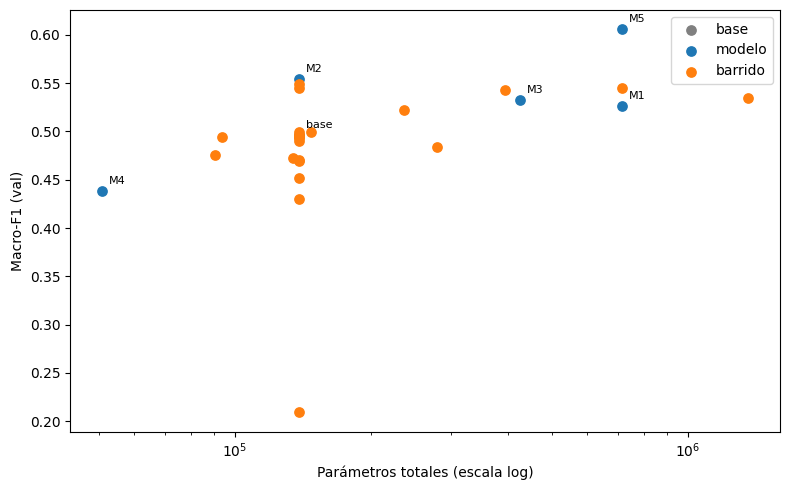

In [ ]:
fig, eje = plt.subplots(figsize=(8, 5))
for g, c in colores.items():
    s = res[res["grupo"] == g]
    eje.scatter(s["parametros"], s["val_macro_f1"], color=c, label=g, s=45)
for _, r in res[res["grupo"].isin(["base", "modelo"])].iterrows():
    eje.annotate(r["experimento"].split("_")[0], (r["parametros"], r["val_macro_f1"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)
eje.set_xscale("log"); eje.set_xlabel("Parámetros totales (escala log)"); eje.set_ylabel("Macro-F1 (val)")
eje.legend(); plt.tight_layout(); plt.show()

## 8. Modelo ganador: repetición con varias semillas y evaluación en test

Se elige la configuración con mayor macro-F1 de validación, se **reentrena con cada semilla de `SEEDS_FINALES`** y se evalúa en test. Es la primera y única vez que se usa el conjunto de test. Reportar media y desviación entre semillas indica cuánto de la diferencia entre configuraciones puede ser azar: si dos configuraciones difieren menos que esa desviación, no son concluyentes.

Como el ganador se escoge entre muchos experimentos sobre validación, su macro-F1 de validación tiende a ser algo optimista. El macro-F1 en test es la estimación imparcial.

In [ ]:
ganador = res.iloc[0]["experimento"]
cfg_ganador = plan[ganador]["cfg"]
print("Ganador:", ganador)
print({k: v for k, v in cfg_ganador.items() if BASE[k] != v} or "(igual al base)")

y_test = test_df["y"].values
finales, modelos_finales = [], {}
for s in SEEDS_FINALES:
    cfg_s = {**cfg_ganador, "SEED_ENTRENAMIENTO": s}
    salida = correr_experimento(f"final_{ganador}_seed{s}", cfg_s, grupo="final", devolver_modelo=True)
    _, _, test_ds = construir_datasets(cfg_s)
    y_pred_t = np.argmax(salida["modelo"].predict(test_ds, verbose=0), axis=-1)
    finales.append({"semilla": s,
                    "val_accuracy": salida["fila"]["val_accuracy"], "val_macro_f1": salida["fila"]["val_macro_f1"],
                    "test_accuracy": round(accuracy_score(y_test, y_pred_t), 4),
                    "test_macro_f1": round(f1_score(y_test, y_pred_t, average="macro"), 4)})
    modelos_finales[s] = {"modelo": salida["modelo"], "history": salida["history"], "y_pred_test": y_pred_t}

finales_df = pd.DataFrame(finales)
finales_df.to_csv(os.path.join(CARPETA_RESULTADOS, "resultados_finales.csv"), index=False)
display(finales_df)
resumen = finales_df.drop(columns="semilla").agg(["mean", "std"]).round(4)
display(resumen)

Ganador: M5_combinacion
{'VOCAB_SIZE': 10000, 'MAX_LEN': 256, 'DROPOUT_RATE': 0.2, 'LEARNING_RATE': 0.001, 'EPOCHS': 30, 'PACIENCIA_EARLY_STOPPING': 3}
Epoch 1/30
573/573 - 17s - 30ms/step - accuracy: 0.4916 - loss: 1.4498 - val_accuracy: 0.5678 - val_loss: 1.0717
Epoch 2/30
573/573 - 17s - 29ms/step - accuracy: 0.6157 - loss: 0.9946 - val_accuracy: 0.6013 - val_loss: 1.0298
Epoch 3/30
573/573 - 18s - 32ms/step - accuracy: 0.6891 - loss: 0.7179 - val_accuracy: 0.6481 - val_loss: 0.9112
Epoch 4/30
573/573 - 14s - 25ms/step - accuracy: 0.7287 - loss: 0.5693 - val_accuracy: 0.6501 - val_loss: 0.9267
Epoch 5/30
573/573 - 15s - 25ms/step - accuracy: 0.7525 - loss: 0.4802 - val_accuracy: 0.6498 - val_loss: 0.9877
Epoch 6/30
573/573 - 14s - 25ms/step - accuracy: 0.7778 - loss: 0.4010 - val_accuracy: 0.6475 - val_loss: 1.0192
→ final_M5_combinacion_seed42: val accuracy = 0.648 | val macro-F1 = 0.593 | 6 épocas | 96 s
Epoch 1/30
573/573 - 18s - 31ms/step - accuracy: 0.4737 - loss: 1.4892 - val_

,semilla,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
0,42,0.6481,0.5928,0.6473,0.5904
1,43,0.6420,0.5886,0.6329,0.5791
2,44,0.6689,0.6098,0.6718,0.6032


,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
mean,0.6530,0.5971,0.6507,0.5909
std,0.0141,0.0112,0.0197,0.0121


### 8.1 Informe por clase y matriz de confusión (test, primera semilla)

                      precision    recall  f1-score   support

             Anxiety      0.671     0.764     0.714       576
             Bipolar      0.689     0.683     0.686       419
          Depression      0.696     0.299     0.418      2294
              Normal      0.860     0.918     0.888      2417
Personality disorder      0.269     0.630     0.377       165
              Stress      0.448     0.497     0.471       388
            Suicidal      0.481     0.725     0.578      1588

            accuracy                          0.647      7847
           macro avg      0.588     0.645     0.590      7847
        weighted avg      0.680     0.647     0.633      7847



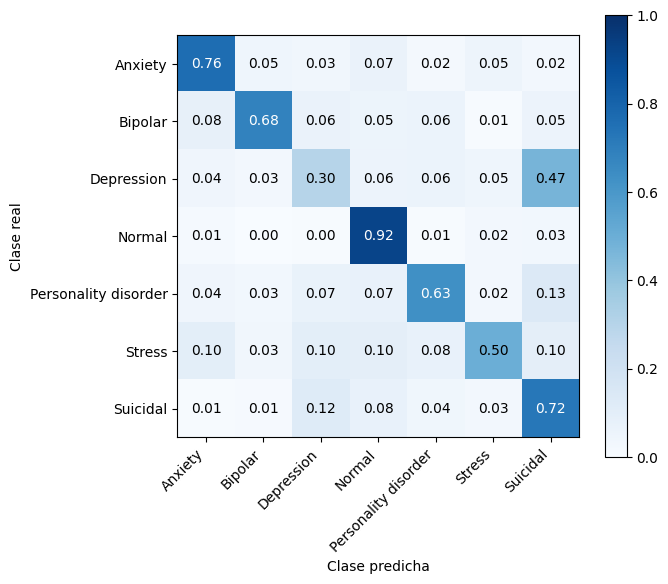

In [ ]:
s0 = SEEDS_FINALES[0]
y_pred_test = modelos_finales[s0]["y_pred_test"]
print(classification_report(y_test, y_pred_test, target_names=nombres_clase, digits=3, zero_division=0))

cm = confusion_matrix(y_test, y_pred_test, normalize="true")
fig, eje = plt.subplots(figsize=(7, 6))
im = eje.imshow(cm, cmap="Blues", vmin=0, vmax=1)
eje.set_xticks(range(NUM_CLASSES)); eje.set_xticklabels(nombres_clase, rotation=45, ha="right")
eje.set_yticks(range(NUM_CLASSES)); eje.set_yticklabels(nombres_clase)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        eje.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
eje.set_xlabel("Clase predicha"); eje.set_ylabel("Clase real")
plt.colorbar(im); plt.tight_layout(); plt.show()

### 8.2 Curvas de entrenamiento del ganador

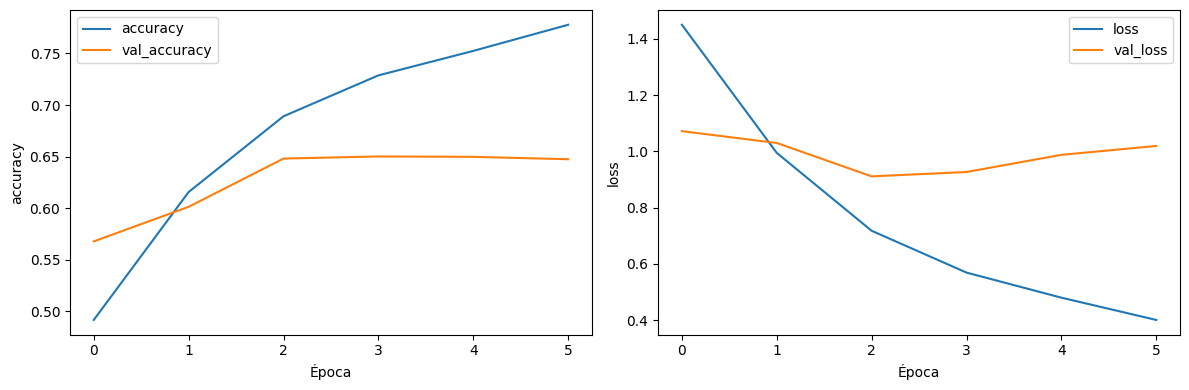

In [ ]:
h = modelos_finales[s0]["history"].history
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, metrica in zip(ejes, ["accuracy", "loss"]):
    eje.plot(h[metrica], label=metrica)
    eje.plot(h["val_" + metrica], label="val_" + metrica)
    eje.set_xlabel("Época"); eje.set_ylabel(metrica); eje.legend()
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import files
for nombre_archivo in ["resultados_consolidados.csv", "resultados_finales.csv"]:
    files.download(os.path.join(CARPETA_RESULTADOS, nombre_archivo))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Predicción sobre un texto nuevo

Se aplica *softmax* a los 7 logits y se toma la clase de mayor probabilidad (`argmax`). Usa el modelo ganador entrenado con la primera semilla.

In [ ]:
modelo_final = modelos_finales[s0]["modelo"]

def predecir(texto):
    logits = modelo_final.predict(tf.constant([texto]), verbose=0)[0]
    probs = tf.nn.softmax(logits).numpy()
    return nombres_clase[int(np.argmax(probs))], dict(zip(nombres_clase, probs.round(3)))

predecir("Últimamente me siento muy triste y sin ganas de hacer nada, no encuentro sentido a mi vida.")

('Depression',
 {'Anxiety': np.float32(0.014),
  'Bipolar': np.float32(0.029),
  'Depression': np.float32(0.462),
  'Normal': np.float32(0.043),
  'Personality disorder': np.float32(0.01),
  'Stress': np.float32(0.032),
  'Suicidal': np.float32(0.409)})